# BC02 — Partie 2 | Analyse exploratoire et statistiques

**Question métier :** le montant net moyen par ligne de vente diffère-t-il entre les ventes avec code promotionnel et celles sans code ? Les données sont observationnelles : vous ne chercherez **pas** à prouver un effet causal.

## Étape 0 — Chargement

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

def trouver_donnees():
    bases = [Path.cwd(), Path.cwd().parent, Path('/content'), Path('/content/CycleNova_Entrainement_RNCP38616')]
    for base in bases:
        for d in (base / 'DONNEES', base / 'CycleNova_Entrainement_RNCP38616' / 'DONNEES'):
            if (d / 'ventes.csv').is_file() and (d / 'produits.csv').is_file() and (d / 'prix_concurrents.csv').is_file():
                return d
    archive = Path('/content/CycleNova_Entrainement_RNCP38616.zip')
    if archive.exists():
        import zipfile
        with zipfile.ZipFile(archive) as z:
            z.extractall('/content')
        return trouver_donnees()
    raise FileNotFoundError('Dossier DONNEES absent. Consultez LISEZMOI.md et conservez la structure des dossiers.')

DATA = trouver_donnees()
produits = pd.read_csv(DATA / 'produits.csv')
ventes = pd.read_csv(DATA / 'ventes.csv')
prix_concurrents = pd.read_csv(DATA / 'prix_concurrents.csv')
print(f'Données chargées : produits={len(produits)}, ventes={len(ventes)}, prix_concurrents={len(prix_concurrents)}')

Données chargées : produits=65, ventes=3005, prix_concurrents=2818


## Étape 1 — Découverte de la donnée

1. Décrivez la granularité et le sens de chaque colonne.
2. Affichez dimensions, types, valeurs manquantes, doublons et distributions.
3. Identifiez des valeurs invalides ; définissez une règle cohérente pour les exclure ou les corriger.

In [2]:
# TODO : affichages et premier audit
df_produits = produits.copy()
print (f'produits : {df_produits.shape[0]}')
df_produits.head(5)

produits : 65


,id_produit,nom_produit,categorie,marque,prix_catalogue,cout_unitaire,actif
0,P0001,Casques - Série 01,Casques,Nord,71.60,42.67,1
1,P0002,Textile - Série 02,Textile,Orbit,78.08,37.45,1
2,P0003,Gants - Série 03,Gants,Roche,31.27,18.96,1
3,P0004,Eclairages - Série 04,Eclairages,Alto,54.57,31.22,1
4,P0005,Antivols - Série 05,Antivols,Nord,36.35,18.33,1


In [3]:
df_produits.shape

(65, 7)

In [4]:
df_produits.info()

<class 'pandas.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id_produit      65 non-null     str    
 1   nom_produit     65 non-null     str    
 2   categorie       65 non-null     str    
 3   marque          65 non-null     str    
 4   prix_catalogue  64 non-null     float64
 5   cout_unitaire   64 non-null     float64
 6   actif           65 non-null     int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 KB


In [5]:
df_produits.isna().sum()

id_produit        0
nom_produit       0
categorie         0
marque            0
prix_catalogue    1
cout_unitaire     1
actif             0
dtype: int64

In [6]:
df_produits.duplicated(keep=False).sum()

np.int64(2)

In [7]:
df_produits.describe()

,prix_catalogue,cout_unitaire,actif
count,64.000000,64.000000,65.000000
mean,60.831563,32.529844,0.938462
std,36.543669,21.395753,0.242186
min,13.860000,7.060000,0.000000
25%,32.582500,16.992500,1.000000
50%,50.450000,29.540000,1.000000
75%,77.345000,40.192500,1.000000
max,161.380000,99.030000,1.000000


In [8]:
df_ventes = ventes.copy()
print (f'ventes : {df_ventes.shape[0]}')
df_ventes.head(5)

ventes : 3005


,id_vente,date_commande,id_produit,quantite,prix_unitaire,taux_remise,code_promo,canal,retour,date_retour,motif_retour
0,V000001,2025-01-06,P0044,2,43.33,0.2,CYCLE20,Application,0.0,NaN,NaN
1,V000002,2025-05-05,P0010,1,69.12,0.0,NaN,Site web,0.0,NaN,NaN
2,V000003,2025-10-02,P0016,1,47.02,0.1,VELO10,Application,0.0,NaN,NaN
3,V000004,2025-09-07,P0029,1,48.81,0.0,NaN,Site web,0.0,NaN,NaN
4,V000005,2025-03-26,P0015,-2,137.05,0.0,NaN,Site web,0.0,NaN,NaN


In [9]:
df_ventes.shape

(3005, 11)

In [10]:
df_ventes.info()

<class 'pandas.DataFrame'>
RangeIndex: 3005 entries, 0 to 3004
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id_vente       3005 non-null   str    
 1   date_commande  3005 non-null   str    
 2   id_produit     2994 non-null   str    
 3   quantite       3005 non-null   int64  
 4   prix_unitaire  2994 non-null   float64
 5   taux_remise    3005 non-null   float64
 6   code_promo     932 non-null    str    
 7   canal          2997 non-null   str    
 8   retour         3000 non-null   float64
 9   date_retour    504 non-null    str    
 10  motif_retour   504 non-null    str    
dtypes: float64(3), int64(1), str(7)
memory usage: 367.3 KB


In [11]:
df_ventes.isna().sum()

id_vente            0
date_commande       0
id_produit         11
quantite            0
prix_unitaire      11
taux_remise         0
code_promo       2073
canal               8
retour              5
date_retour      2501
motif_retour     2501
dtype: int64

In [12]:
df_ventes.duplicated(keep=False).sum()

np.int64(10)

In [13]:
df_ventes.describe()

,quantite,prix_unitaire,taux_remise,retour
count,3005.000000,2994.000000,3005.000000,3000.000000
mean,1.416306,59.687515,0.048586,0.170000
std,0.735762,36.782786,0.092515,0.379229
min,-2.000000,-15.000000,-0.200000,0.000000
25%,1.000000,30.685000,0.000000,0.000000
50%,1.000000,49.180000,0.000000,0.000000
75%,2.000000,77.700000,0.100000,0.000000
max,4.000000,174.130000,1.500000,2.000000


In [14]:
df_prix_concurrents = prix_concurrents.copy()
print (f'prix_concurrents : {df_prix_concurrents.shape[0]}')
df_prix_concurrents.head(5)

prix_concurrents : 2818


,id_produit,concurrent,date_releve,prix_concurrent
0,P0001,Concurrent A,2025-01-01,64.67
1,P0001,Concurrent B,2025-01-01,61.06
2,P0002,Concurrent A,2025-01-01,61.54
3,P0002,Concurrent B,2025-01-01,87.09
4,P0003,Concurrent A,2025-01-01,36.28


In [15]:
df_prix_concurrents.shape

(2818, 4)

In [16]:
df_prix_concurrents.info()

<class 'pandas.DataFrame'>
RangeIndex: 2818 entries, 0 to 2817
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_produit       2818 non-null   str    
 1   concurrent       2818 non-null   str    
 2   date_releve      2818 non-null   str    
 3   prix_concurrent  2812 non-null   float64
dtypes: float64(1), str(3)
memory usage: 162.5 KB


In [17]:
df_prix_concurrents.isna().sum()

id_produit         0
concurrent         0
date_releve        0
prix_concurrent    6
dtype: int64

In [18]:
df_prix_concurrents.duplicated(keep=False).sum()

np.int64(4)

In [19]:
df_prix_concurrents.describe()

,prix_concurrent
count,2812.000000
mean,60.118201
std,37.431411
min,-9.000000
25%,30.780000
50%,50.365000
75%,79.580000
max,197.280000


colonnes : produits = une ligne par produit, ventes = une ligne par produit vendu (quantite, prix_unitaire, taux_remise entre 0 et 1, code_promo), prix_concurrents = un relevé de prix par ligne (pas utilisé ici).

In [20]:
# anomalies dans les ventes
print (f"doublons : {df_ventes.duplicated().sum()}")

doublons : 5


In [21]:
print (f"id_produit manquants : {df_ventes['id_produit'].isna().sum()}")

id_produit manquants : 11


In [22]:
# produits inconnus = produits renseignés moins ceux qui existent dans la table produits
connus = df_ventes['id_produit'].isin(df_produits['id_produit']).sum()
print (f"id_produit inconnus : {df_ventes['id_produit'].notna().sum() - connus}")

id_produit inconnus : 8


In [23]:
print (f"quantite <= 0 : {(df_ventes['quantite'] <= 0).sum()}")

quantite <= 0 : 7


In [24]:
print (f"prix_unitaire <= 0 : {(df_ventes['prix_unitaire'] <= 0).sum()}")

prix_unitaire <= 0 : 5


In [25]:
print (f"taux_remise < 0 : {(df_ventes['taux_remise'] < 0).sum()}")
print (f"taux_remise > 1 : {(df_ventes['taux_remise'] > 1).sum()}")

taux_remise < 0 : 4
taux_remise > 1 : 4


règle : je garde une vente seulement si elle n'est pas en double, si le produit existe, si la quantité est plus grande que 0, si le prix est plus grand que 0 et si la remise est entre 0 et 1. j'enlève les lignes fausses sans les corriger parce que je ne connais pas la vraie valeur. je ne filtre pas retour et canal car je n'en ai pas besoin pour le montant net.

## Étape 2 — Préparation argumentée

1. Construisez `montant_net = quantite * prix_unitaire * (1 - taux_remise)` pour des lignes valides.
2. Définissez `avec_promo` à partir de `code_promo` non vide.
3. Écartez les doublons de ventes, les quantités/prix/remises invalides et les produits inexistants ; expliquez vos critères.
4. Décrivez l’effet des exclusions sur la taille de l’échantillon.

In [26]:
# je nettoie une règle à la fois
df_propre = df_ventes.drop_duplicates()
print (f'après doublons : {df_propre.shape[0]}')

après doublons : 3000


In [27]:
df_propre = df_propre[df_propre['id_produit'].isin(df_produits['id_produit'])]
print (f'après produits connus : {df_propre.shape[0]}')

après produits connus : 2981


In [28]:
df_propre = df_propre[df_propre['quantite'] > 0]
print (f'après quantite > 0 : {df_propre.shape[0]}')

après quantite > 0 : 2974


In [29]:
# un prix manquant est aussi enlevé ici
df_propre = df_propre[df_propre['prix_unitaire'] > 0]
print (f'après prix > 0 : {df_propre.shape[0]}')

après prix > 0 : 2958


In [30]:
df_propre = df_propre[df_propre['taux_remise'] >= 0]
df_propre = df_propre[df_propre['taux_remise'] <= 1]
print (f'après remise entre 0 et 1 : {df_propre.shape[0]}')

après remise entre 0 et 1 : 2950


In [31]:
# nouvelles colonnes
df_propre = df_propre.copy()
df_propre['montant_net'] = df_propre['quantite'] * df_propre['prix_unitaire'] * (1 - df_propre['taux_remise'])
df_propre['avec_promo'] = df_propre['code_promo'].notna()
df_propre.head()

,id_vente,date_commande,id_produit,quantite,prix_unitaire,taux_remise,code_promo,canal,retour,date_retour,motif_retour,montant_net,avec_promo
0,V000001,2025-01-06,P0044,2,43.33,0.2,CYCLE20,Application,0.0,NaN,NaN,69.328,True
1,V000002,2025-05-05,P0010,1,69.12,0.0,NaN,Site web,0.0,NaN,NaN,69.120,False
2,V000003,2025-10-02,P0016,1,47.02,0.1,VELO10,Application,0.0,NaN,NaN,42.318,True
3,V000004,2025-09-07,P0029,1,48.81,0.0,NaN,Site web,0.0,NaN,NaN,48.810,False
5,V000006,2025-08-19,P0018,1,53.43,0.0,NaN,Site web,0.0,NaN,NaN,53.430,False


In [32]:
# les deux groupes
df_promo = df_propre[df_propre['avec_promo'] == True]
df_sans_promo = df_propre[df_propre['avec_promo'] == False]
print (f'avec promo : {df_promo.shape[0]}')
print (f'sans promo : {df_sans_promo.shape[0]}')

avec promo : 915
sans promo : 2035


on passe de 3005 lignes à 2950, donc 55 lignes enlevées (1,8 %). c'est peu. une ligne est soit avec code promo soit sans, donc les deux groupes sont indépendants.

## Étape 3 — Descriptif et graphiques

Calculez taille, moyenne, médiane, écart-type et IQR par groupe. Créez **au moins deux** visualisations appropriées (par exemple boxplot et histogramme). Expliquez la différence entre moyenne et médiane en présence de valeurs extrêmes.

In [33]:
# groupe avec promo
m = df_promo['montant_net']
print (f'taille : {m.shape[0]}')
print (f'moyenne : {m.mean()}')
print (f'médiane : {m.median()}')
print (f'écart-type : {m.std()}')
print (f'IQR : {m.quantile(0.75) - m.quantile(0.25)}')

taille : 915
moyenne : 71.60727868852459
médiane : 55.064
écart-type : 59.11515400711512
IQR : 59.20225


In [34]:
# groupe sans promo
m = df_sans_promo['montant_net']
print (f'taille : {m.shape[0]}')
print (f'moyenne : {m.mean()}')
print (f'médiane : {m.median()}')
print (f'écart-type : {m.std()}')
print (f'IQR : {m.quantile(0.75) - m.quantile(0.25)}')

taille : 2035
moyenne : 85.12127272727272
médiane : 66.31
écart-type : 70.23752947678877
IQR : 68.55499999999999


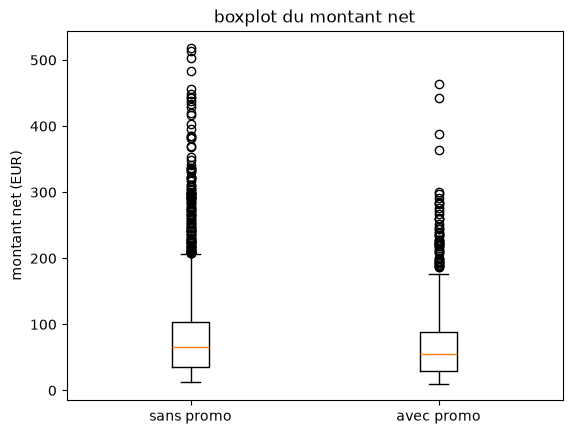

In [35]:
import matplotlib.pyplot as plt

plt.boxplot([df_sans_promo['montant_net'], df_promo['montant_net']])
plt.xticks([1, 2], ['sans promo', 'avec promo'])
plt.title('boxplot du montant net')
plt.ylabel('montant net (EUR)')
plt.show()

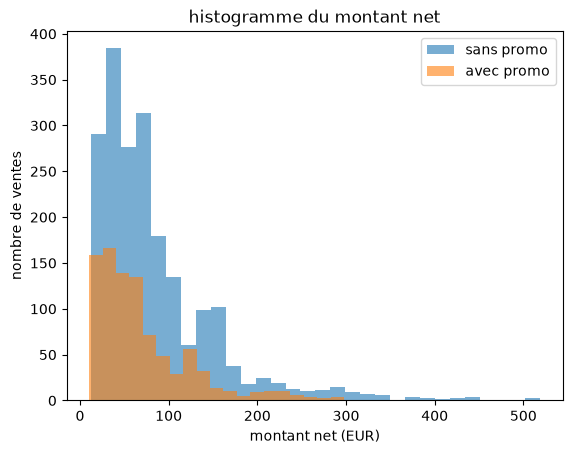

In [36]:
plt.hist(df_sans_promo['montant_net'], bins=30, alpha=0.6, label='sans promo')
plt.hist(df_promo['montant_net'], bins=30, alpha=0.6, label='avec promo')
plt.title('histogramme du montant net')
plt.xlabel('montant net (EUR)')
plt.ylabel('nombre de ventes')
plt.legend()
plt.show()

la moyenne est plus haute que la médiane dans les deux groupes. quelques très grosses ventes tirent la moyenne vers le haut alors que la médiane (la valeur du milieu) bouge peu. sans promo : moyenne 85, médiane 66. avec promo : moyenne 72, médiane 55.

## Étape 4 — Hypothèse et test statistique

1. Énoncez H0 et H1 clairement pour les moyennes.
2. Justifiez le choix du test (par exemple t de Welch, avec réserves sur l’indépendance et la distribution).
3. Annoncez alpha = 0,05 avant de regarder la p-value.
4. Calculez la p-value et interprétez le résultat sans conclure à une causalité.

## Étape 5 — Conclusion

Proposez une conclusion métier nuancée : tailles des groupes, différence observée, résultat du test, importance pratique de l’écart, limites et pistes de vérification.

il y a 915 lignes avec code promo et 2035 sans. le montant net moyen est de 71,6 € avec promo contre 85,1 € sans, soit 13,5 € de moins (environ 16 %). cet écart est observé sur nos données. il est assez petit, et une partie vient juste de la remise (15 % en moyenne avec promo, 0 % sans). limites : pas de cause prouvée, pas d'identifiant client, montants étalés vers le haut, 55 lignes enlevées. pour aller plus loin : comparer produit par produit, comparer les codes VELO10 et CYCLE20, regarder le nombre de ventes et la marge, refaire l'analyse sur 2025 puis 2026.